In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import os
from dotenv import load_dotenv
load_dotenv()
import tidy3d as td
from tidy3d import web
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import sys
import pandas as pd


from AutomationModule import *

import AutomationModule as AM

In [2]:
tidy3dAPI = os.environ["API_TIDY3D_KEY"]

In [ ]:
a = 1
n=1.53
medium = td.Medium(permittivity=n**2)
run = True

In [4]:
lambdas =  1/np.array([0.15,0.85])

In [5]:
# Rod radius for the network. The rod endpoints are already supplied in physical
# units (point density ~1, node-to-node spacing ~0.8), so the same rod radius that
# was used for the Delaunay-derived FST network applies here directly.
rod_radius = 0.1

In [ ]:
# The rods are supplied as END-TO-END endpoint pairs (two consecutive rows per rod)
# already in physical units and centered on the origin, so NO Delaunay triangulation
# and NO density rescaling are needed (compare the FST-network notebook).
folder_path = rf"./Structures/networks"
polarization = "TM"
add_field_monitor = True
project_name = fr"20261019 Transmission gyromorphs - Network from Rods {polarization} r_{rod_radius}{" Field" if add_field_monitor else ""}_n{n}"
empty = False
runtime_ps = 20e-12
min_steps_per_lambda = 15
id0 = ""
add_ref = True
# Box matches the extent of the supplied networks: x in [-50, 50], y in [-10, 10]
# ("h20" -> height 20 in the filenames).
Lx, Ly = 100, 20

In [7]:
# Load every network file as an array of rod segments.
# Each CSV lists the two endpoints of every rod on consecutive rows (x, y, z),
# so reshaping to (n_rods, 2, 2) recovers the segments directly.
files = sorted(f for f in os.listdir(folder_path) if f.endswith(".csv"))

data = []
for f in files:
    df = pd.read_csv(os.path.join(folder_path, f))
    pts = df[["x", "y"]].to_numpy()
    assert len(pts) % 2 == 0, f"{f}: odd number of endpoints"
    segs = pts.reshape(-1, 2, 2)  # (n_rods, 2 endpoints, 2 coords)

    # Center on the origin (data is already centered, this is a safety net).
    xmin, xmax = pts[:, 0].min(), pts[:, 0].max()
    ymin, ymax = pts[:, 1].min(), pts[:, 1].max()
    cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
    segs = segs - np.array([cx, cy])

    L = np.linalg.norm(segs[:, 1] - segs[:, 0], axis=1)
    print(f"{Path(f).stem}")
    print(f"  n_rods = {len(segs)}")
    print(f"  x range: [{xmin - cx:.4f}, {xmax - cx:.4f}]  Lx = {xmax - xmin:.4f}")
    print(f"  y range: [{ymin - cy:.4f}, {ymax - cy:.4f}]  Ly = {ymax - ymin:.4f}")
    print(f"  rod length: min {L.min():.3f}, median {np.median(L):.3f}, max {L.max():.3f}")
    data.append(segs)

ewaldscatterer2d_120.dat_rot90.0_single_layer_h20
  n_rods = 3500
  x range: [-49.9753, 49.9753]  Lx = 99.9506
  y range: [-9.9756, 9.9756]  Ly = 19.9512
  rod length: min 0.363, median 0.776, max 1.596
ewaldscatterer2d_180.dat_rot90.0_single_layer_h20
  n_rods = 3481
  x range: [-49.9457, 49.9457]  Lx = 99.8914
  y range: [-9.9958, 9.9958]  Ly = 19.9917
  rod length: min 0.372, median 0.788, max 1.544
ewaldscatterer2d_1layers.dat_rot90.0_single_layer_h20
  n_rods = 3500
  x range: [-49.9753, 49.9753]  Lx = 99.9506
  y range: [-9.9756, 9.9756]  Ly = 19.9512
  rod length: min 0.363, median 0.776, max 1.596
ewaldscatterer2d_240.dat_rot90.0_single_layer_h20
  n_rods = 3199
  x range: [-49.9505, 49.9505]  Lx = 99.9009
  y range: [-9.9922, 9.9922]  Ly = 19.9843
  rod length: min 0.336, median 0.811, max 1.506
ewaldscatterer2d_2layers.dat_rot90.0_single_layer_h20
  n_rods = 3283
  x range: [-49.9563, 49.9563]  Lx = 99.9126
  y range: [-9.9821, 9.9821]  Ly = 19.9643
  rod length: min 0.382, m

## Network construction from supplied rod endpoints

Unlike the FST notebook (which derives the network from a point pattern via a
Delaunay triangulation of the points and joins edge-sharing triangle centroids),
here the network is supplied directly as the **end-to-end positions of the rods**.

Each CSV in `Structures/networks/` lists, for every rod, the coordinates of its two
endpoints on two consecutive rows. So building the dielectric network reduces to:

1. Read the endpoints and reshape into `(n_rods, 2, 2)` segments.
2. Clip each segment to the simulation box.
3. Represent each rod as a `td.PolySlab` (a thin rectangle in the xy-plane extruded
   along z) and place a small `td.Cylinder` cap at each node so neighbouring rods
   join without mitering gaps.

The endpoints are already in physical units (node spacing ~0.8, matching the density=1
FST network) and centered on the origin, so no rescaling is applied.

In [8]:
def clip_segment_to_box(p1, p2, xmin, xmax, ymin, ymax):
    """Liang-Barsky clip of segment p1->p2 against an axis-aligned box. Returns (q1, q2) or None."""
    x1, y1 = p1
    x2, y2 = p2
    dx, dy = x2 - x1, y2 - y1
    p = [-dx, dx, -dy, dy]
    q = [x1 - xmin, xmax - x1, y1 - ymin, ymax - y1]
    u1, u2 = 0.0, 1.0
    for pi, qi in zip(p, q):
        if pi == 0:
            if qi < 0:
                return None
        else:
            t = qi / pi
            if pi < 0:
                if t > u2:
                    return None
                u1 = max(u1, t)
            else:
                if t < u1:
                    return None
                u2 = min(u2, t)
    if u1 > u2:
        return None
    return (np.array([x1 + u1*dx, y1 + u1*dy]),
            np.array([x1 + u2*dx, y1 + u2*dy]))


def build_network_from_segments(segments, rod_radius, Lx, Ly):
    """Build the dielectric network from supplied rod endpoint pairs.

    Parameters
    ----------
    segments : (n_rods, 2, 2) ndarray
        Endpoint pairs for each rod in real units (already centered/scaled).
    rod_radius : float
        Half-thickness of the rods.
    Lx, Ly : float
        Simulation box size; rods/nodes outside |x|<=Lx/2, |y|<=Ly/2 are clipped.

    Returns
    -------
    list[td.Geometry]
        Rod polygons and node caps to be wrapped in a td.GeometryGroup.
    """
    xmin, xmax = -Lx / 2.0, Lx / 2.0
    ymin, ymax = -Ly / 2.0, Ly / 2.0

    rod_geoms = []
    node_points = []

    for (p1, p2) in segments:
        clipped = clip_segment_to_box(p1, p2, xmin, xmax, ymin, ymax)
        if clipped is None:
            continue
        q1, q2 = clipped

        d = q2 - q1
        L = np.linalg.norm(d)
        if L < 1e-10:
            continue
        d /= L
        n = np.array([-d[1], d[0]])  # left-perpendicular unit vector

        verts = [
            tuple(q1 + rod_radius * n),
            tuple(q2 + rod_radius * n),
            tuple(q2 - rod_radius * n),
            tuple(q1 - rod_radius * n),
        ]
        rod_geoms.append(
            td.PolySlab(vertices=verts, slab_bounds=(-td.inf, td.inf), axis=2)
        )

        node_points.append(tuple(q1))
        node_points.append(tuple(q2))

    # Deduplicated caps so rod joints don't have miter gaps
    cap_geoms = []
    seen_caps = set()
    for x, y in node_points:
        key = (round(float(x), 8), round(float(y), 8))
        if key in seen_caps:
            continue
        seen_caps.add(key)
        cap_geoms.append(
            td.Cylinder(center=[float(x), float(y), 0.0], radius=rod_radius, length=td.inf)
        )

    return rod_geoms + cap_geoms

ewaldscatterer2d_120.dat_rot90.0_single_layer_h20: 3500 rods, 2404 nodes


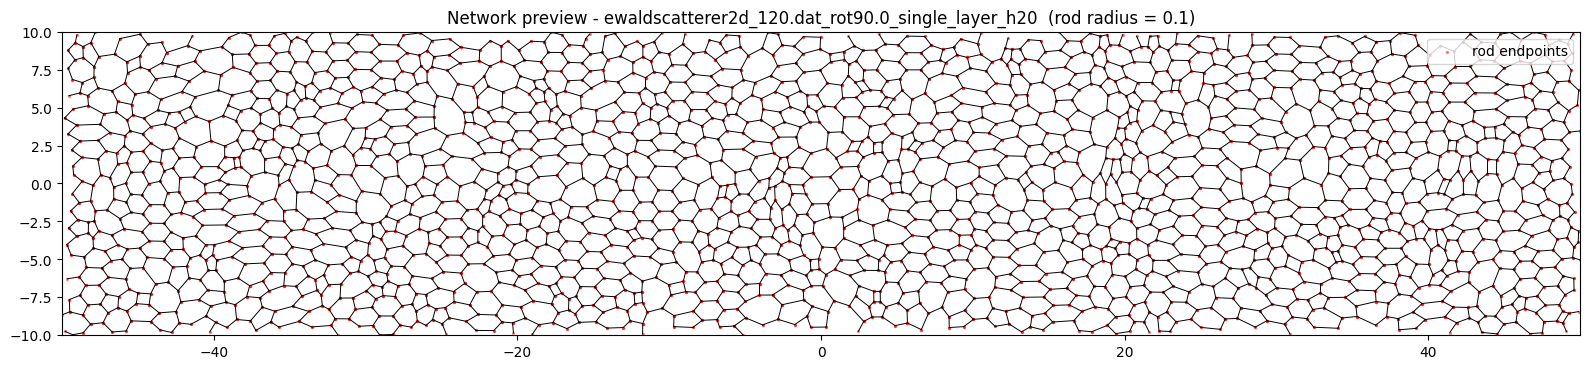

ewaldscatterer2d_180.dat_rot90.0_single_layer_h20: 3481 rods, 2389 nodes


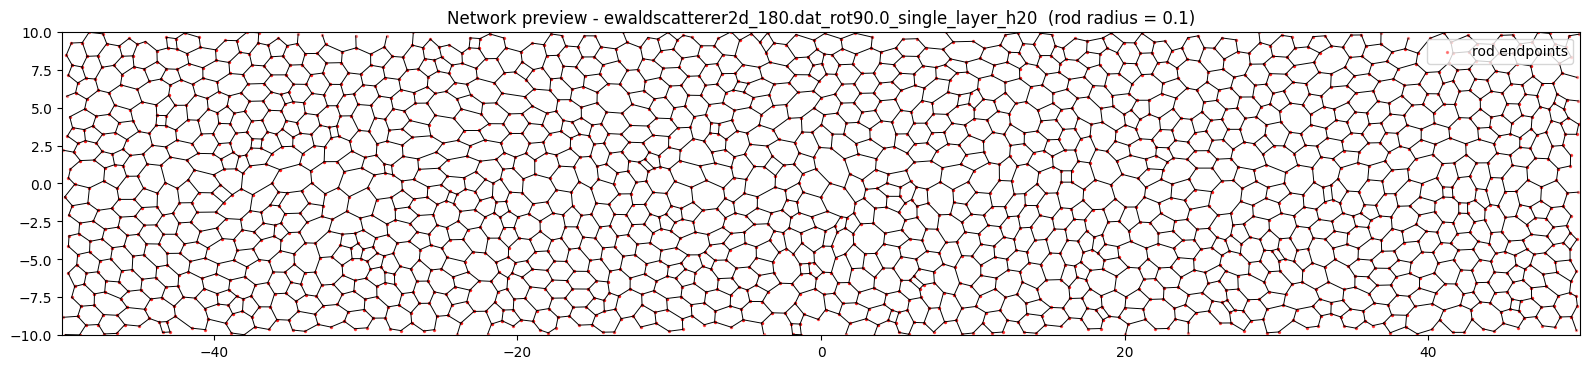

ewaldscatterer2d_1layers.dat_rot90.0_single_layer_h20: 3500 rods, 2404 nodes


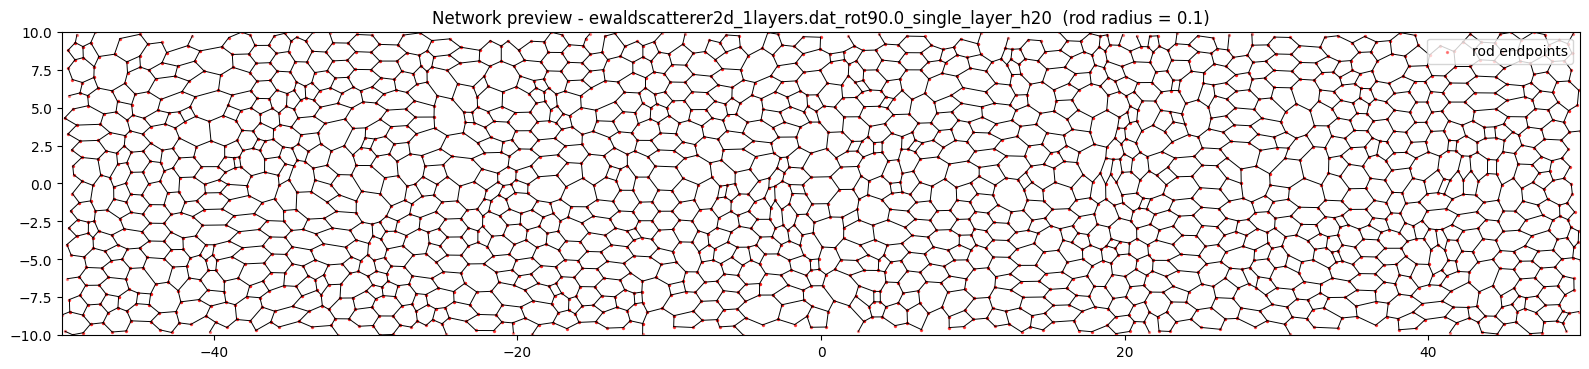

ewaldscatterer2d_240.dat_rot90.0_single_layer_h20: 3199 rods, 2200 nodes


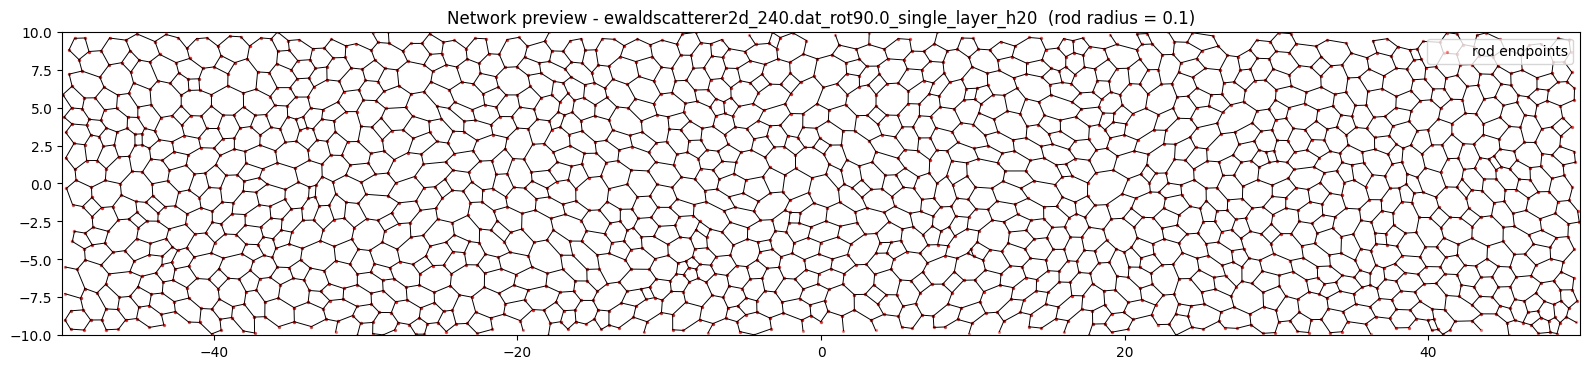

ewaldscatterer2d_2layers.dat_rot90.0_single_layer_h20: 3283 rods, 2253 nodes


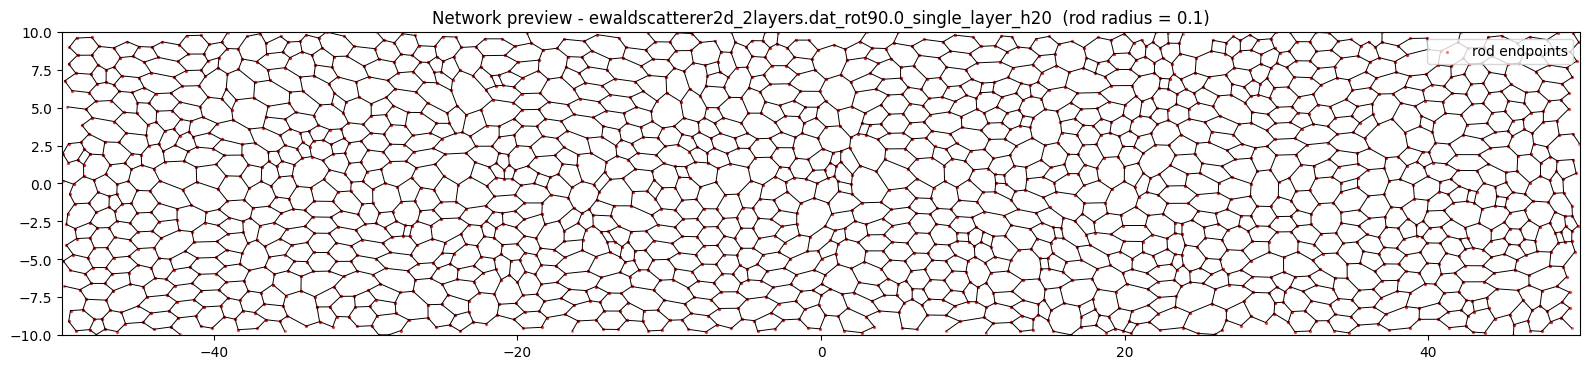

ewaldscatterer2d_300.dat_rot90.0_single_layer_h20: 2765 rods, 1909 nodes


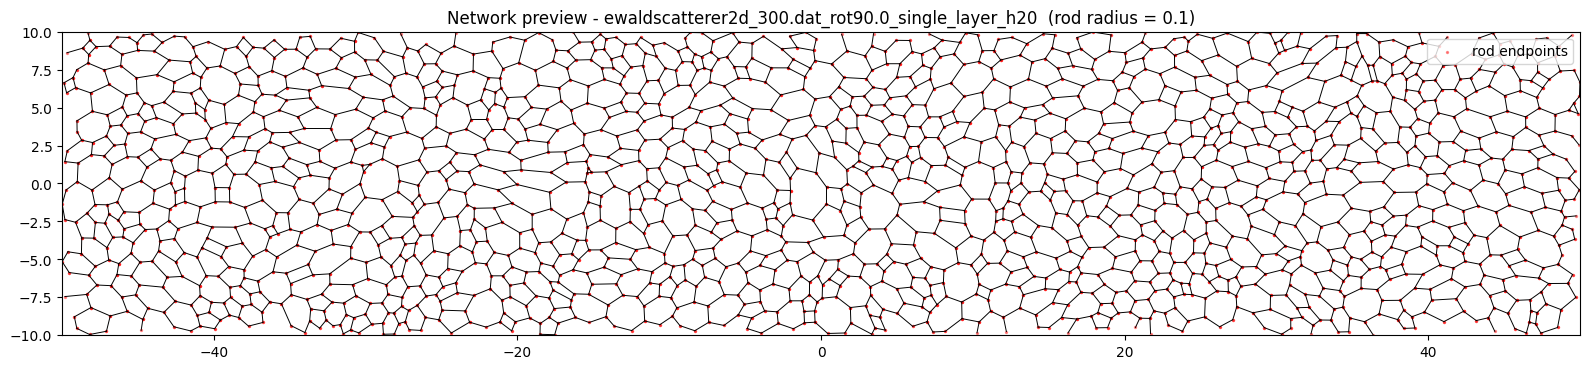

ewaldscatterer2d_360.dat_rot90.0_single_layer_h20: 2541 rods, 1755 nodes


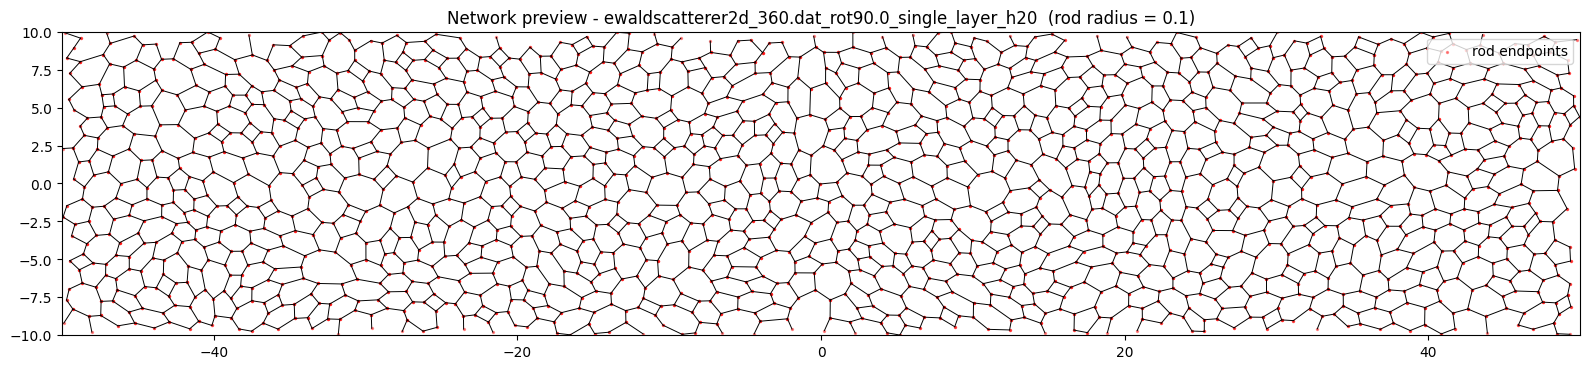

ewaldscatterer2d_3layers.dat_rot90.0_single_layer_h20: 3038 rods, 2088 nodes


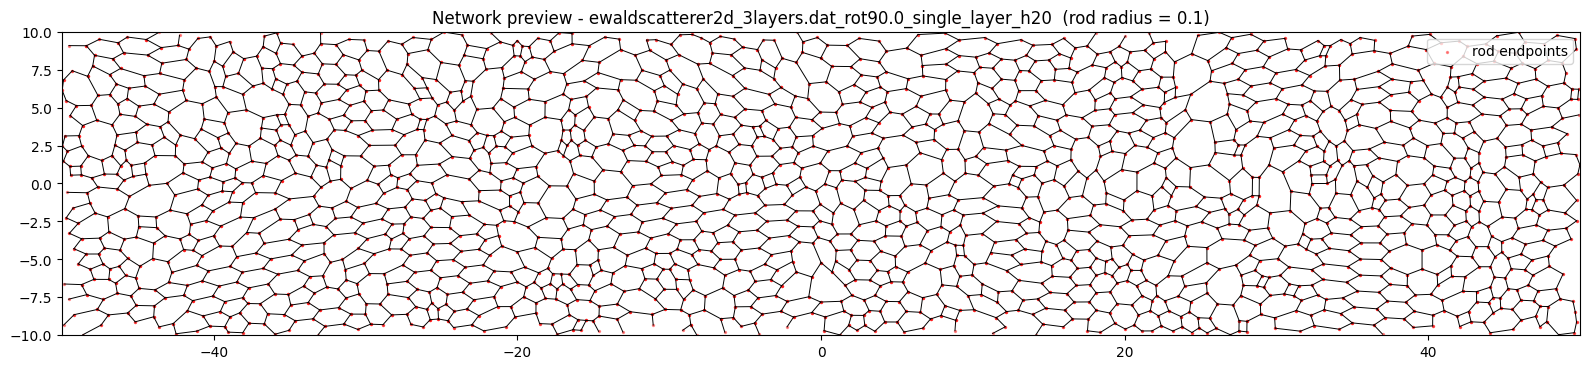

ewaldscatterer2d_4layers.dat_rot90.0_single_layer_h20: 3023 rods, 2078 nodes


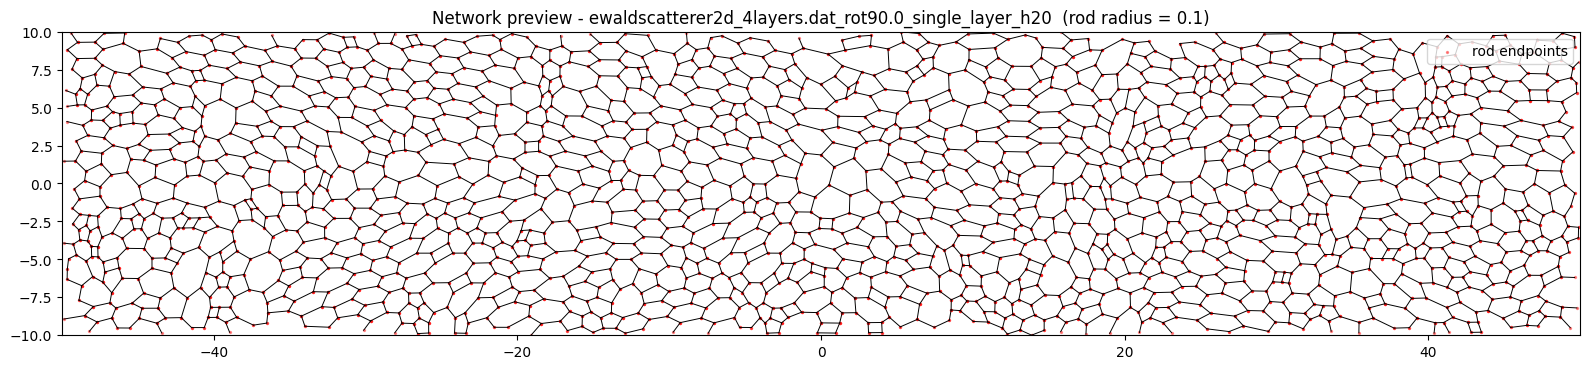

ewaldscatterer2d_5layers.dat_rot90.0_single_layer_h20: 2925 rods, 2013 nodes


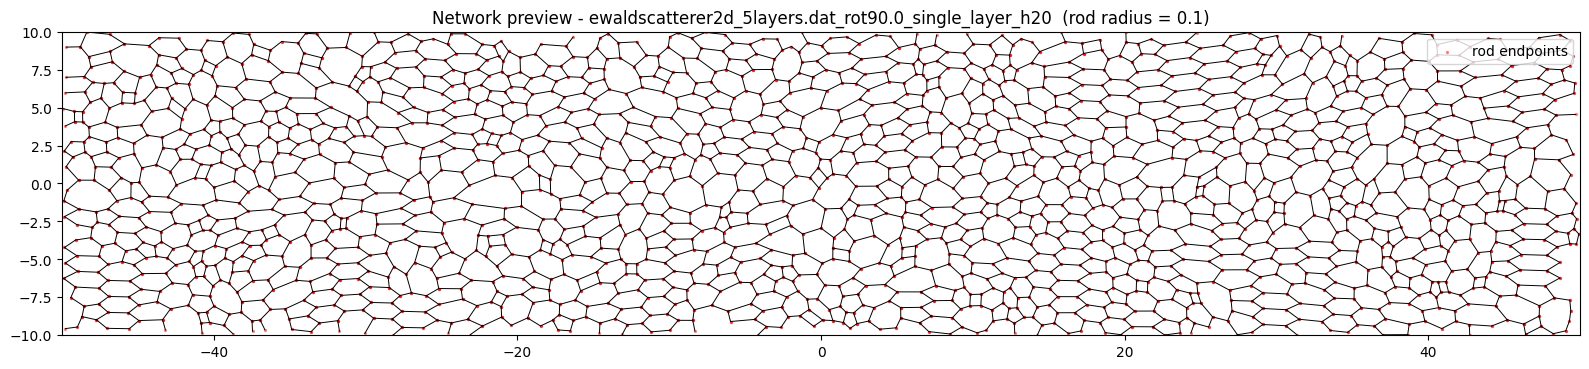

ewaldscatterer2d_60.dat_rot90.0_single_layer_h20: 3476 rods, 2389 nodes


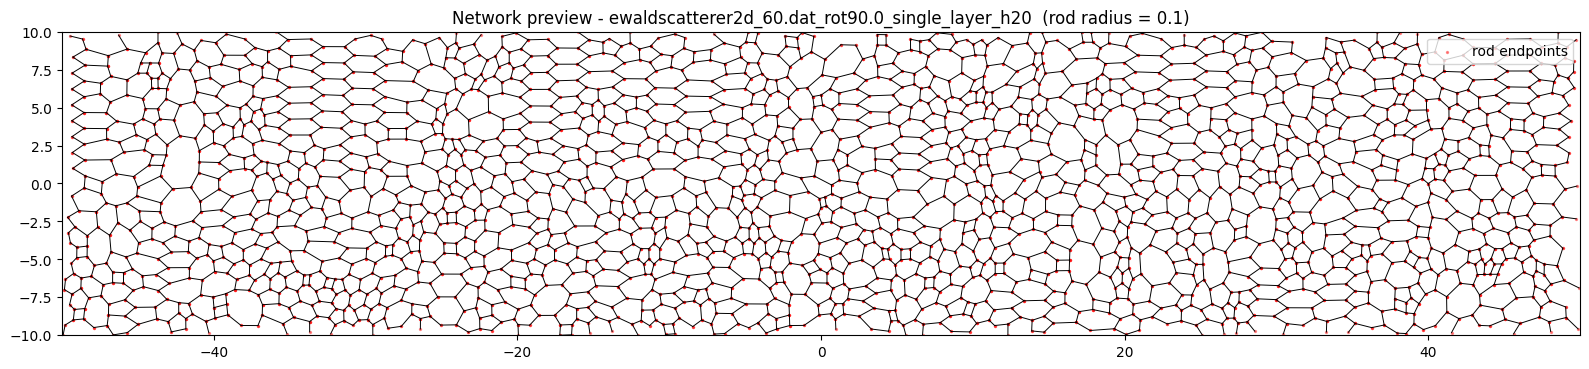

In [9]:
# Quick sanity-check plot of the network for each input structure before launching anything.
for k, segs in enumerate(data):
    geoms = build_network_from_segments(segs, rod_radius=rod_radius, Lx=Lx, Ly=Ly)
    n_rods = sum(1 for g in geoms if isinstance(g, td.PolySlab))
    n_caps = sum(1 for g in geoms if isinstance(g, td.Cylinder))
    print(f"{Path(files[k]).stem}: {n_rods} rods, {n_caps} nodes")

    fig, ax = plt.subplots(1, 1, figsize=(16, 4), tight_layout=True)
    # Draw the network skeleton (clipped centerlines) for a fast preview
    for (p1, p2) in segs:
        clipped = clip_segment_to_box(p1, p2, -Lx/2, Lx/2, -Ly/2, Ly/2)
        if clipped is None:
            continue
        q1, q2 = clipped
        ax.plot([q1[0], q2[0]], [q1[1], q2[1]], 'k-', linewidth=0.7)
    nodes = segs.reshape(-1, 2)
    ax.scatter(nodes[:, 0], nodes[:, 1], s=2, color='red', alpha=0.4, label='rod endpoints')
    ax.set_xlim(-Lx/2, Lx/2)
    ax.set_ylim(-Ly/2, Ly/2)
    ax.set_aspect('equal')
    ax.set_title(f"Network preview - {Path(files[k]).stem}  (rod radius = {rod_radius})")
    ax.legend(loc='upper right')
    plt.show()

ewaldscatterer2d_120.dat_rot90.0_single_layer_h20 Network Transmission 6.67 - 1.18
Configured successfully.


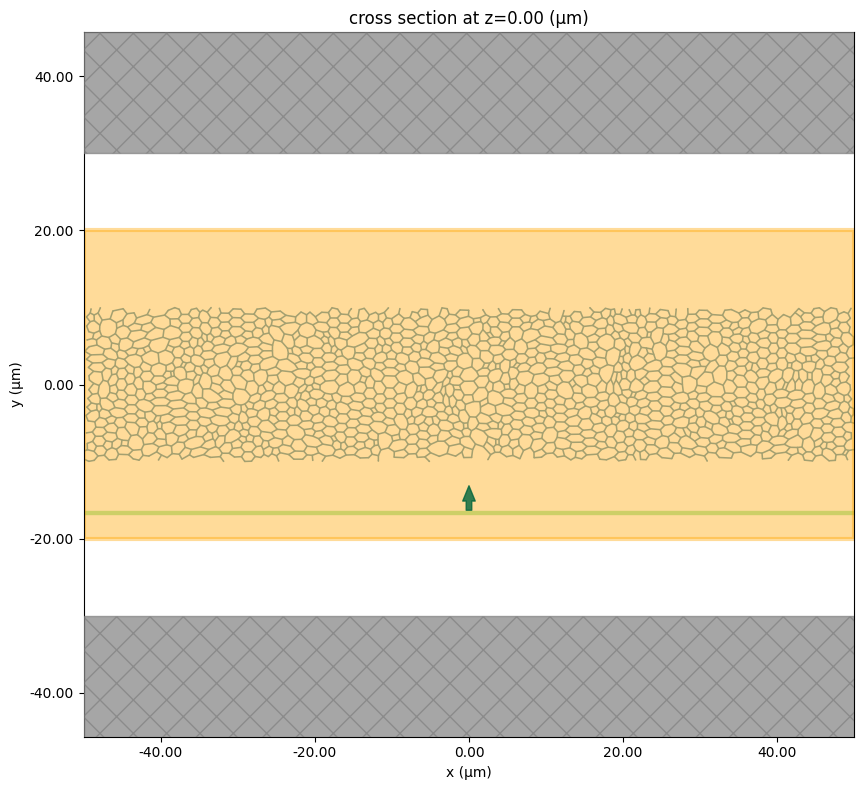

11:09:05 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_120.dat_rot90.0_single_layer_
                                 h20 Network Transmission 6.67 - 1.18_0' with   
                                 task_id                                        
                                 'fdve-4d74443c-8557-4e90-8b3f-3d1c3ace0f4a' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=188266;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4d74443c-8557-4e90-8b3f-3d1c3ace0f4a\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=926739;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4d74443c-8557-4e90-8b3f-3d1c3ace0f4a\task]8;;\
                                 ]8;id=926739;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4d74443c-8557-4e90-8b3f-3d1c3ace0f4a\Id]8;;\]8;id=188266;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4d74443c-8557-4e90-8b3f-3d1c3ace0f4a\=]8;;\]8;id=845558;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4d74443c-8557-4e90-8b3f-3d1c3ace0f4a\fdve]8;;\]8;id=188266;https://tidy3d.simulation.cloud/workbench?taskId=fdve-4d74443c-8557-4e90-8b3f-3d1c3ace0f4a\-4d74443c-8557-4e90-8b3f-3d1c3ace0f4a']8;;\.

                                 Task folder: ]8;id=673731;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=673731;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:09:07 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

11:09:08 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_120.dat_rot90.0_single_layer_
                                 h20 Network Transmission 6.67 - 1.18' with     
                                 task_id                                        
                                 'fdve-f9573cd0-752f-4edf-85f3-3a86f5680a2d' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=987765;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f9573cd0-752f-4edf-85f3-3a86f5680a2d\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=690158;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f9573cd0-752f-4edf-85f3-3a86f5680a2d\task]8;;\
                                 ]8;id=690158;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f9573cd0-752f-4edf-85f3-3a86f5680a2d\Id]8;;\]8;id=987765;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f9573cd0-752f-4edf-85f3-3a86f5680a2d\=]8;;\]8;id=702252;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f9573cd0-752f-4edf-85f3-3a86f5680a2d\fdve]8;;\]8;id=987765;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f9573cd0-752f-4edf-85f3-3a86f5680a2d\-f9573cd0-752f-4edf-85f3-3a86f5680a2d']8;;\.

                                 Task folder: ]8;id=119175;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=119175;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:09:14 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

Folder '../../../data/20260707 Transmission gyromorphs - Network from Rods TM r_0.1 Field/ewaldscatterer2d_120.dat_rot90.0_single_layer_h20' created successfully.
ewaldscatterer2d_180.dat_rot90.0_single_layer_h20 Network Transmission 6.67 - 1.18
Configured successfully.


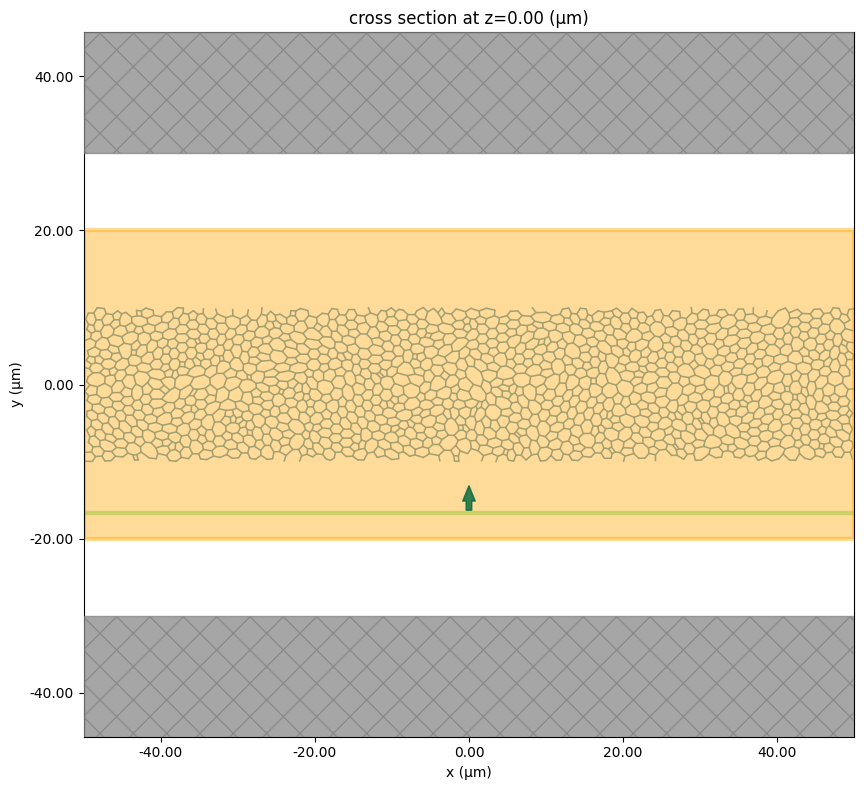

11:09:20 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_180.dat_rot90.0_single_layer_
                                 h20 Network Transmission 6.67 - 1.18' with     
                                 task_id                                        
                                 'fdve-3c929e4c-3b7f-420b-ac57-9701a36bb875' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=207275;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3c929e4c-3b7f-420b-ac57-9701a36bb875\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=250025;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3c929e4c-3b7f-420b-ac57-9701a36bb875\task]8;;\
                                 ]8;id=250025;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3c929e4c-3b7f-420b-ac57-9701a36bb875\Id]8;;\]8;id=207275;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3c929e4c-3b7f-420b-ac57-9701a36bb875\=]8;;\]8;id=542530;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3c929e4c-3b7f-420b-ac57-9701a36bb875\fdve]8;;\]8;id=207275;https://tidy3d.simulation.cloud/workbench?taskId=fdve-3c929e4c-3b7f-420b-ac57-9701a36bb875\-3c929e4c-3b7f-420b-ac57-9701a36bb875']8;;\.

                                 Task folder: ]8;id=570809;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=570809;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:09:26 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

Folder '../../../data/20260707 Transmission gyromorphs - Network from Rods TM r_0.1 Field/ewaldscatterer2d_180.dat_rot90.0_single_layer_h20' created successfully.
ewaldscatterer2d_1layers.dat_rot90.0_single_layer_h20 Network Transmission 6.67 - 1.18
Configured successfully.


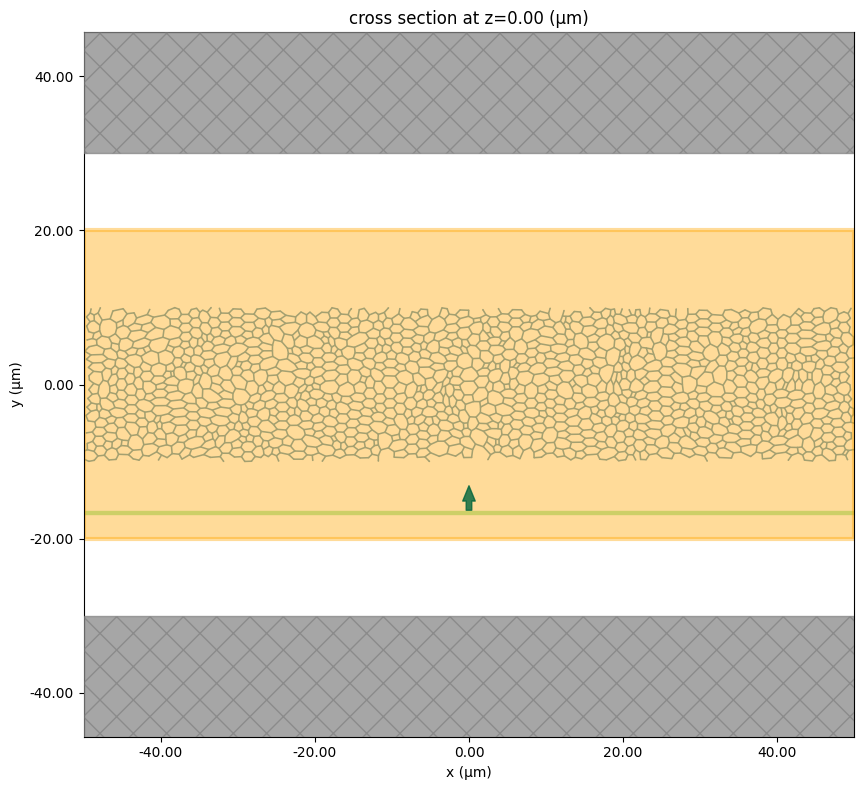

11:09:31 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_1layers.dat_rot90.0_single_la
                                 yer_h20 Network Transmission 6.67 - 1.18' with 
                                 task_id                                        
                                 'fdve-fa78a321-5e56-4369-a3f2-923e9cc1a0cc' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=685799;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fa78a321-5e56-4369-a3f2-923e9cc1a0cc\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=3523;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fa78a321-5e56-4369-a3f2-923e9cc1a0cc\task]8;;\
                                 ]8;id=3523;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fa78a321-5e56-4369-a3f2-923e9cc1a0cc\Id]8;;\]8;id=685799;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fa78a321-5e56-4369-a3f2-923e9cc1a0cc\=]8;;\]8;id=153575;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fa78a321-5e56-4369-a3f2-923e9cc1a0cc\fdve]8;;\]8;id=685799;https://tidy3d.simulation.cloud/workbench?taskId=fdve-fa78a321-5e56-4369-a3f2-923e9cc1a0cc\-fa78a321-5e56-4369-a3f2-923e9cc1a0cc']8;;\.

                                 Task folder: ]8;id=810549;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=810549;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:09:37 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

Folder '../../../data/20260707 Transmission gyromorphs - Network from Rods TM r_0.1 Field/ewaldscatterer2d_1layers.dat_rot90.0_single_layer_h20' created successfully.
ewaldscatterer2d_240.dat_rot90.0_single_layer_h20 Network Transmission 6.67 - 1.18
Configured successfully.


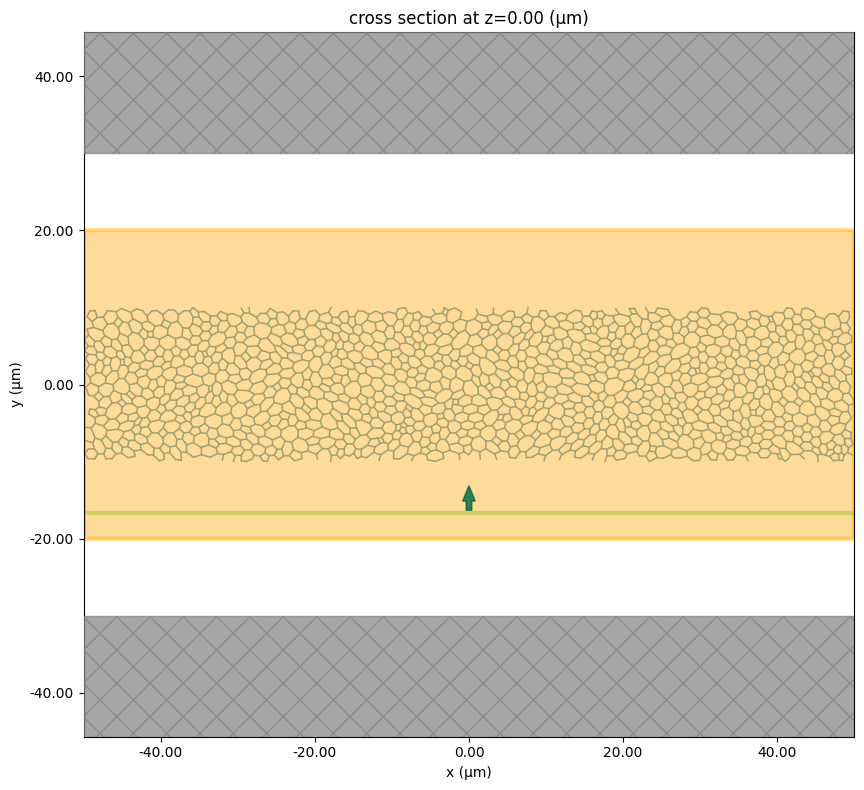

11:09:43 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_240.dat_rot90.0_single_layer_
                                 h20 Network Transmission 6.67 - 1.18' with     
                                 task_id                                        
                                 'fdve-7836f2c8-e890-452a-8ea5-c87ecd20e90c' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=28835;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7836f2c8-e890-452a-8ea5-c87ecd20e90c\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=104339;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7836f2c8-e890-452a-8ea5-c87ecd20e90c\task]8;;\
                                 ]8;id=104339;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7836f2c8-e890-452a-8ea5-c87ecd20e90c\Id]8;;\]8;id=28835;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7836f2c8-e890-452a-8ea5-c87ecd20e90c\=]8;;\]8;id=174946;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7836f2c8-e890-452a-8ea5-c87ecd20e90c\fdve]8;;\]8;id=28835;https://tidy3d.simulation.cloud/workbench?taskId=fdve-7836f2c8-e890-452a-8ea5-c87ecd20e90c\-7836f2c8-e890-452a-8ea5-c87ecd20e90c']8;;\.

                                 Task folder: ]8;id=555626;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=555626;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:09:48 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

Folder '../../../data/20260707 Transmission gyromorphs - Network from Rods TM r_0.1 Field/ewaldscatterer2d_240.dat_rot90.0_single_layer_h20' created successfully.
ewaldscatterer2d_2layers.dat_rot90.0_single_layer_h20 Network Transmission 6.67 - 1.18
Configured successfully.


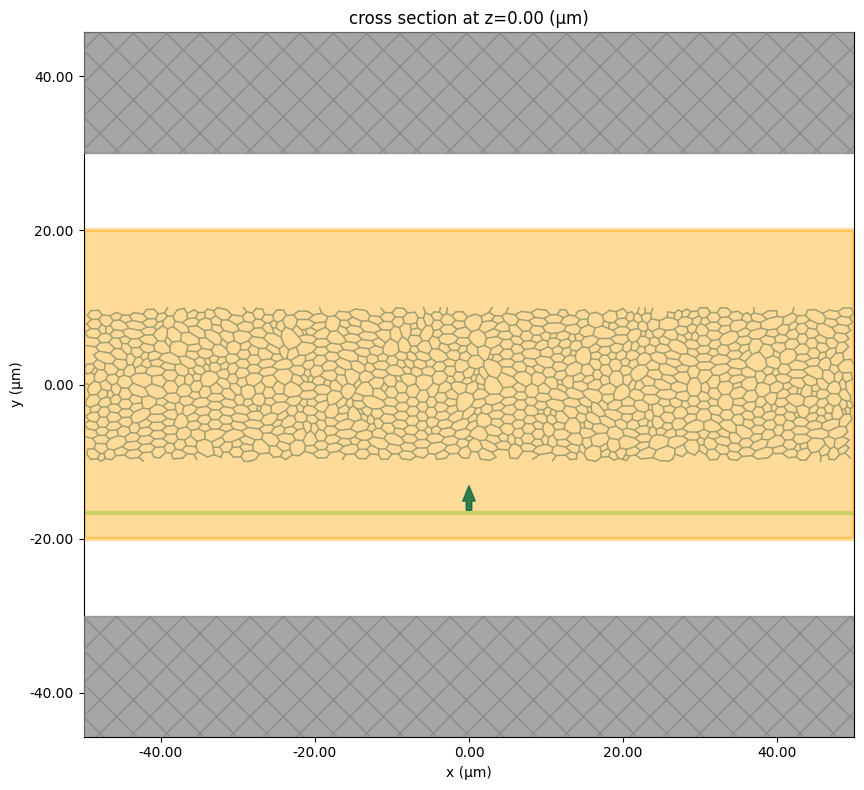

11:09:53 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_2layers.dat_rot90.0_single_la
                                 yer_h20 Network Transmission 6.67 - 1.18' with 
                                 task_id                                        
                                 'fdve-f4159453-6fbb-4b35-94ac-c6d3cd8220f2' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=640486;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f4159453-6fbb-4b35-94ac-c6d3cd8220f2\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=360443;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f4159453-6fbb-4b35-94ac-c6d3cd8220f2\task]8;;\
                                 ]8;id=360443;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f4159453-6fbb-4b35-94ac-c6d3cd8220f2\Id]8;;\]8;id=640486;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f4159453-6fbb-4b35-94ac-c6d3cd8220f2\=]8;;\]8;id=713174;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f4159453-6fbb-4b35-94ac-c6d3cd8220f2\fdve]8;;\]8;id=640486;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f4159453-6fbb-4b35-94ac-c6d3cd8220f2\-f4159453-6fbb-4b35-94ac-c6d3cd8220f2']8;;\.

                                 Task folder: ]8;id=89823;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=89823;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:09:59 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

Folder '../../../data/20260707 Transmission gyromorphs - Network from Rods TM r_0.1 Field/ewaldscatterer2d_2layers.dat_rot90.0_single_layer_h20' created successfully.
ewaldscatterer2d_300.dat_rot90.0_single_layer_h20 Network Transmission 6.67 - 1.18
Configured successfully.


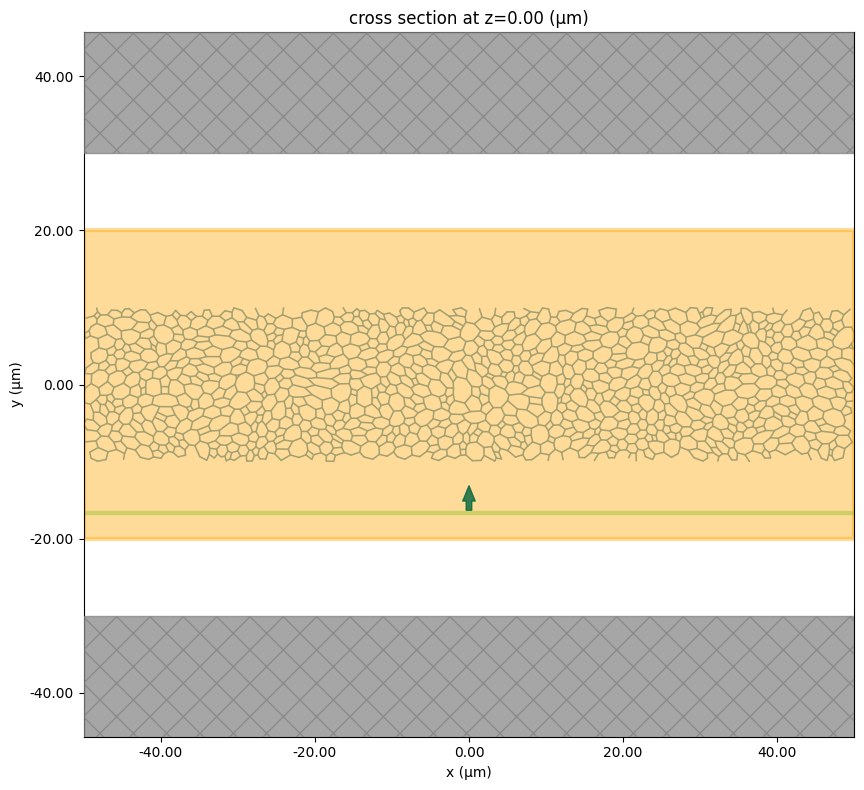

11:10:03 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_300.dat_rot90.0_single_layer_
                                 h20 Network Transmission 6.67 - 1.18' with     
                                 task_id                                        
                                 'fdve-ef6f2397-bb0a-4016-8e78-b22117cab24c' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=66392;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ef6f2397-bb0a-4016-8e78-b22117cab24c\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=846650;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ef6f2397-bb0a-4016-8e78-b22117cab24c\task]8;;\
                                 ]8;id=846650;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ef6f2397-bb0a-4016-8e78-b22117cab24c\Id]8;;\]8;id=66392;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ef6f2397-bb0a-4016-8e78-b22117cab24c\=]8;;\]8;id=469727;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ef6f2397-bb0a-4016-8e78-b22117cab24c\fdve]8;;\]8;id=66392;https://tidy3d.simulation.cloud/workbench?taskId=fdve-ef6f2397-bb0a-4016-8e78-b22117cab24c\-ef6f2397-bb0a-4016-8e78-b22117cab24c']8;;\.

                                 Task folder: ]8;id=659292;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=659292;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:10:09 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

Folder '../../../data/20260707 Transmission gyromorphs - Network from Rods TM r_0.1 Field/ewaldscatterer2d_300.dat_rot90.0_single_layer_h20' created successfully.
ewaldscatterer2d_360.dat_rot90.0_single_layer_h20 Network Transmission 6.67 - 1.18
Configured successfully.


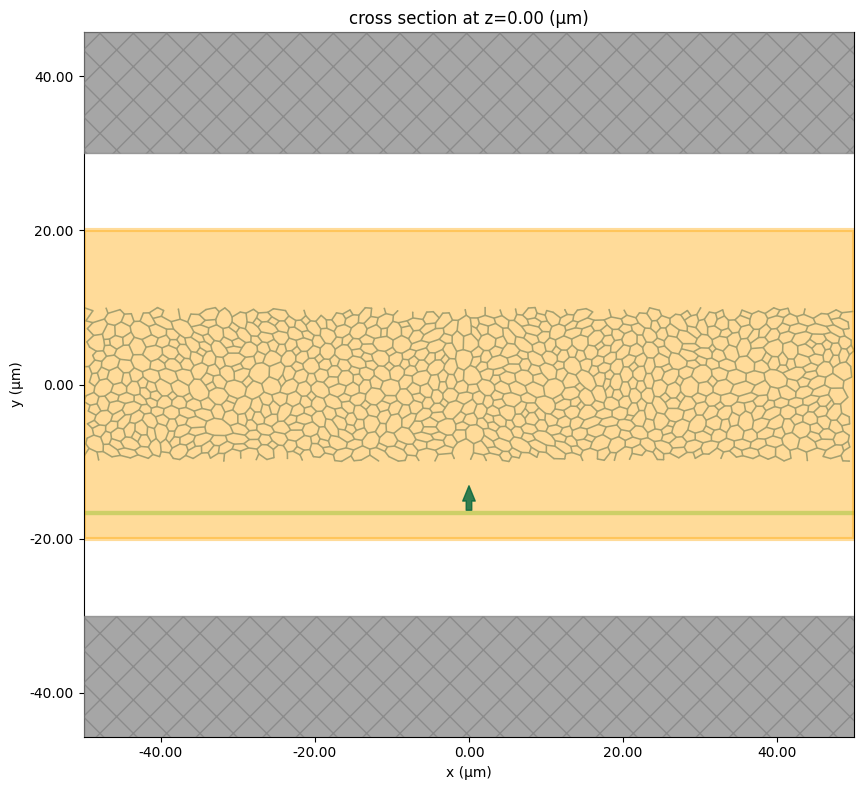

11:10:13 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_360.dat_rot90.0_single_layer_
                                 h20 Network Transmission 6.67 - 1.18' with     
                                 task_id                                        
                                 'fdve-c1341c35-6eb8-4fcf-b5b6-9b18b43c0938' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=761114;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c1341c35-6eb8-4fcf-b5b6-9b18b43c0938\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=273747;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c1341c35-6eb8-4fcf-b5b6-9b18b43c0938\task]8;;\
                                 ]8;id=273747;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c1341c35-6eb8-4fcf-b5b6-9b18b43c0938\Id]8;;\]8;id=761114;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c1341c35-6eb8-4fcf-b5b6-9b18b43c0938\=]8;;\]8;id=110415;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c1341c35-6eb8-4fcf-b5b6-9b18b43c0938\fdve]8;;\]8;id=761114;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c1341c35-6eb8-4fcf-b5b6-9b18b43c0938\-c1341c35-6eb8-4fcf-b5b6-9b18b43c0938']8;;\.

                                 Task folder: ]8;id=793348;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=793348;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:10:18 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

Folder '../../../data/20260707 Transmission gyromorphs - Network from Rods TM r_0.1 Field/ewaldscatterer2d_360.dat_rot90.0_single_layer_h20' created successfully.
ewaldscatterer2d_3layers.dat_rot90.0_single_layer_h20 Network Transmission 6.67 - 1.18
Configured successfully.


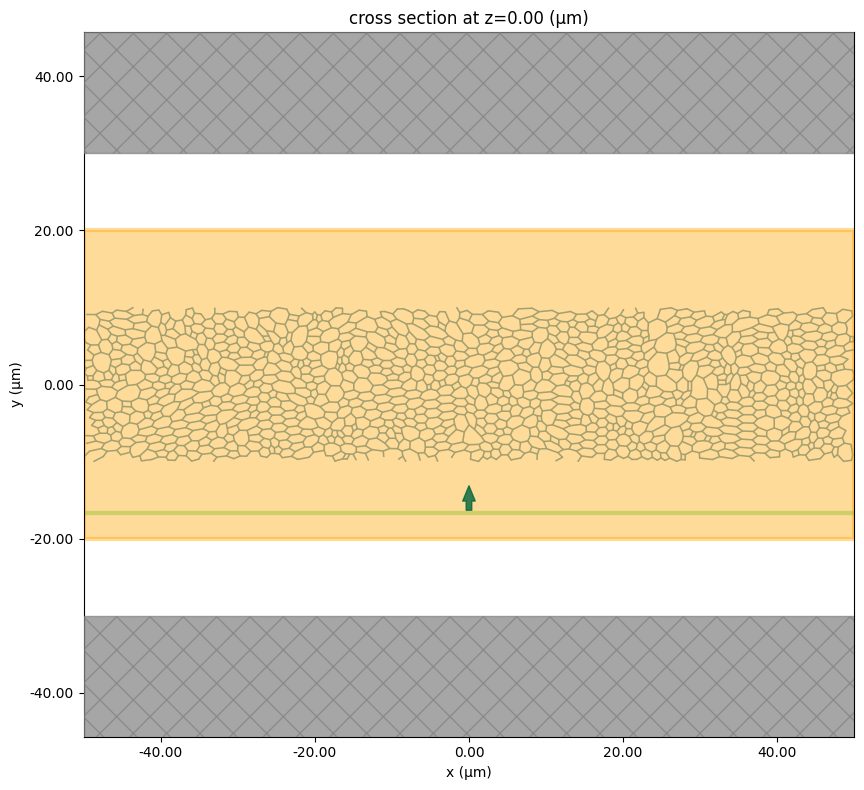

11:10:23 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_3layers.dat_rot90.0_single_la
                                 yer_h20 Network Transmission 6.67 - 1.18' with 
                                 task_id                                        
                                 'fdve-c68effe3-c645-4f53-81f2-1df1b42d7cff' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=412862;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c68effe3-c645-4f53-81f2-1df1b42d7cff\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=744114;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c68effe3-c645-4f53-81f2-1df1b42d7cff\task]8;;\
                                 ]8;id=744114;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c68effe3-c645-4f53-81f2-1df1b42d7cff\Id]8;;\]8;id=412862;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c68effe3-c645-4f53-81f2-1df1b42d7cff\=]8;;\]8;id=16184;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c68effe3-c645-4f53-81f2-1df1b42d7cff\fdve]8;;\]8;id=412862;https://tidy3d.simulation.cloud/workbench?taskId=fdve-c68effe3-c645-4f53-81f2-1df1b42d7cff\-c68effe3-c645-4f53-81f2-1df1b42d7cff']8;;\.

                                 Task folder: ]8;id=280925;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=280925;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:10:29 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

Folder '../../../data/20260707 Transmission gyromorphs - Network from Rods TM r_0.1 Field/ewaldscatterer2d_3layers.dat_rot90.0_single_layer_h20' created successfully.
ewaldscatterer2d_4layers.dat_rot90.0_single_layer_h20 Network Transmission 6.67 - 1.18
Configured successfully.


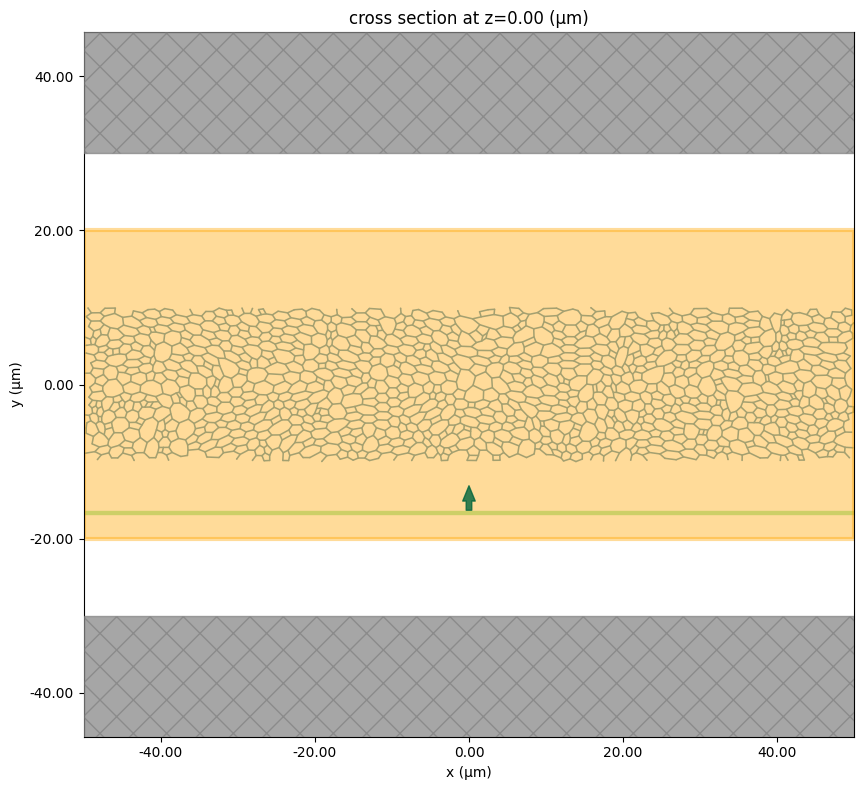

11:10:34 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_4layers.dat_rot90.0_single_la
                                 yer_h20 Network Transmission 6.67 - 1.18' with 
                                 task_id                                        
                                 'fdve-47283355-ca38-4538-b9bf-b947e068bb1d' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=136432;https://tidy3d.simulation.cloud/workbench?taskId=fdve-47283355-ca38-4538-b9bf-b947e068bb1d\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=905535;https://tidy3d.simulation.cloud/workbench?taskId=fdve-47283355-ca38-4538-b9bf-b947e068bb1d\task]8;;\
                                 ]8;id=905535;https://tidy3d.simulation.cloud/workbench?taskId=fdve-47283355-ca38-4538-b9bf-b947e068bb1d\Id]8;;\]8;id=136432;https://tidy3d.simulation.cloud/workbench?taskId=fdve-47283355-ca38-4538-b9bf-b947e068bb1d\=]8;;\]8;id=617659;https://tidy3d.simulation.cloud/workbench?taskId=fdve-47283355-ca38-4538-b9bf-b947e068bb1d\fdve]8;;\]8;id=136432;https://tidy3d.simulation.cloud/workbench?taskId=fdve-47283355-ca38-4538-b9bf-b947e068bb1d\-47283355-ca38-4538-b9bf-b947e068bb1d']8;;\.

                                 Task folder: ]8;id=490099;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=490099;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:10:39 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

Folder '../../../data/20260707 Transmission gyromorphs - Network from Rods TM r_0.1 Field/ewaldscatterer2d_4layers.dat_rot90.0_single_layer_h20' created successfully.
ewaldscatterer2d_5layers.dat_rot90.0_single_layer_h20 Network Transmission 6.67 - 1.18
Configured successfully.


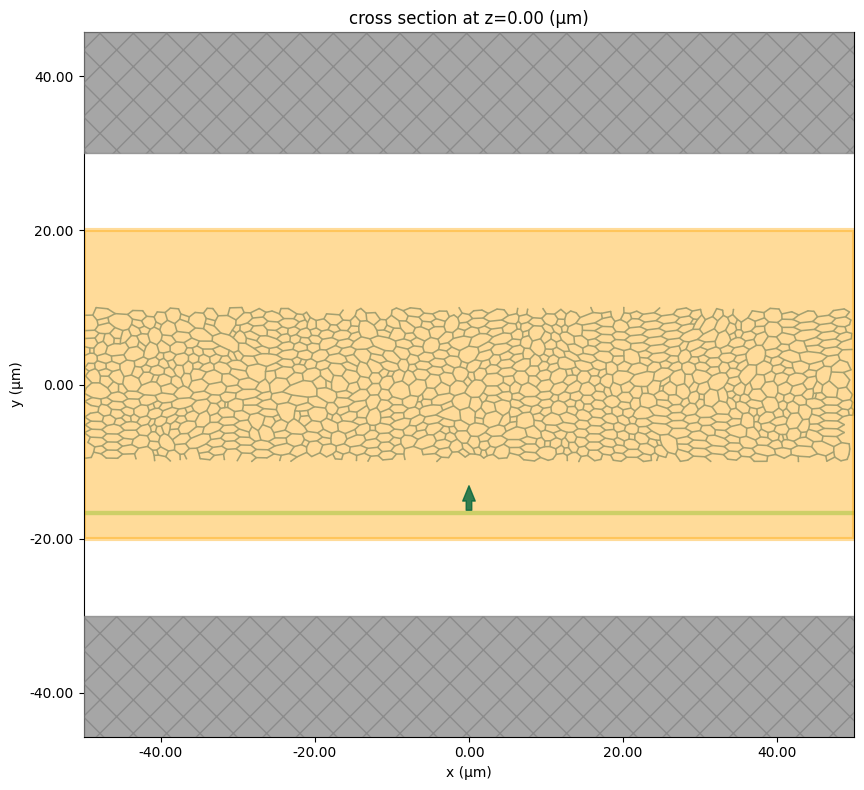

11:10:45 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_5layers.dat_rot90.0_single_la
                                 yer_h20 Network Transmission 6.67 - 1.18' with 
                                 task_id                                        
                                 'fdve-d21cec7b-013e-4d1d-95c1-264c622ef2f8' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=484298;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d21cec7b-013e-4d1d-95c1-264c622ef2f8\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=958845;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d21cec7b-013e-4d1d-95c1-264c622ef2f8\task]8;;\
                                 ]8;id=958845;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d21cec7b-013e-4d1d-95c1-264c622ef2f8\Id]8;;\]8;id=484298;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d21cec7b-013e-4d1d-95c1-264c622ef2f8\=]8;;\]8;id=494142;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d21cec7b-013e-4d1d-95c1-264c622ef2f8\fdve]8;;\]8;id=484298;https://tidy3d.simulation.cloud/workbench?taskId=fdve-d21cec7b-013e-4d1d-95c1-264c622ef2f8\-d21cec7b-013e-4d1d-95c1-264c622ef2f8']8;;\.

                                 Task folder: ]8;id=134361;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=134361;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:10:50 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

Folder '../../../data/20260707 Transmission gyromorphs - Network from Rods TM r_0.1 Field/ewaldscatterer2d_5layers.dat_rot90.0_single_layer_h20' created successfully.
ewaldscatterer2d_60.dat_rot90.0_single_layer_h20 Network Transmission 6.67 - 1.18
Configured successfully.


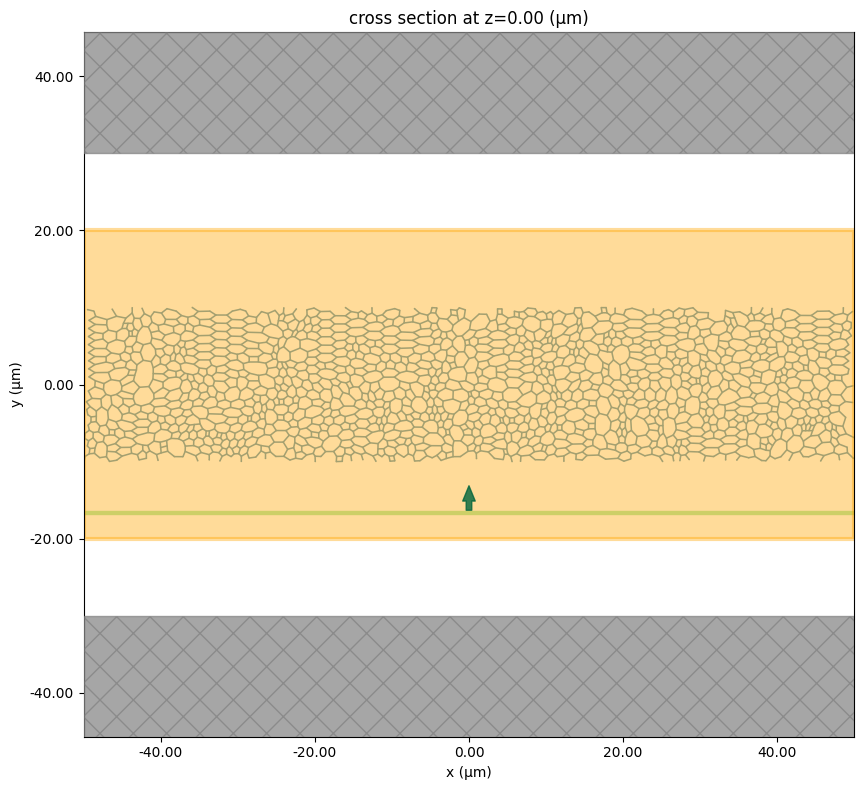

11:10:56 W. Europe Daylight Time Created task                                   
                                 'ewaldscatterer2d_60.dat_rot90.0_single_layer_h
                                 20 Network Transmission 6.67 - 1.18' with      
                                 task_id                                        
                                 'fdve-f7ceaa9b-4412-460f-ba9f-86c1d5a0e705' and
                                 task_type 'FDTD'.

                                 View task using web UI at                      
                                 ]8;id=308370;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f7ceaa9b-4412-460f-ba9f-86c1d5a0e705\'https://tidy3d.simulation.cloud/workbench?]8;;\]8;id=261791;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f7ceaa9b-4412-460f-ba9f-86c1d5a0e705\task]8;;\
                                 ]8;id=261791;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f7ceaa9b-4412-460f-ba9f-86c1d5a0e705\Id]8;;\]8;id=308370;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f7ceaa9b-4412-460f-ba9f-86c1d5a0e705\=]8;;\]8;id=698528;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f7ceaa9b-4412-460f-ba9f-86c1d5a0e705\fdve]8;;\]8;id=308370;https://tidy3d.simulation.cloud/workbench?taskId=fdve-f7ceaa9b-4412-460f-ba9f-86c1d5a0e705\-f7ceaa9b-4412-460f-ba9f-86c1d5a0e705']8;;\.

                                 Task folder: ]8;id=316856;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\'20260707 Transmission gyromorphs ]8;;\
                                 ]8;id=316856;https://tidy3d.simulation.cloud/folders/folder-02da5d21-b5d7-4998-b5d9-c13c1e042d75\- Network from Rods TM r_0.1 Field']8;;\.

Output()

11:11:02 W. Europe Daylight Time Maximum FlexCredit cost: 1.388. Minimum cost   
                                 depends on task execution details. Use         
                                 'web.real_cost(task_id)' to get the billed     
                                 FlexCredit cost after a simulation run.

Folder '../../../data/20260707 Transmission gyromorphs - Network from Rods TM r_0.1 Field/ewaldscatterer2d_60.dat_rot90.0_single_layer_h20' created successfully.


In [10]:
for k, segs in enumerate(data):
        run_name = f"{Path(files[k]).stem} Network Transmission {lambdas[0]:.3g} - {lambdas[1]:.3g}"
        print(run_name)

        structure_1 = AM.loadAndRunStructure(key = tidy3dAPI
                    ,direction="z", lambda_range=lambdas,
                    box_size= 50,runtime_ps=runtime_ps,min_steps_per_lambda=min_steps_per_lambda,
                   scaling=1,shuoff_condtion=1e-20, verbose=True,
                   monitors=["flux"],
                   freqs=250,
                   source="planewave",
                   width=0.35, ref_only=True
                   )


        sim = structure_1.sim

        boundaries= td.BoundarySpec(
                y=td.Boundary(plus=td.Absorber(num_layers=200),minus=td.Absorber(num_layers=200)),
                x=td.Boundary.periodic(),
                z=td.Boundary.periodic(),
            )
        sim = sim.copy(update={'boundary_spec':boundaries})
        sim = sim.copy(update={'sources':[]})
        sim = sim.copy(update={'monitors':[]})


        sim = sim.copy(update={'size':[Lx,Ly+40,0]})

        source = td.PlaneWave(
                source_time = td.GaussianPulse(
                    freq0=structure_1.freq0,
                    fwidth=structure_1.freqw
                ),
                size= (td.inf,0,td.inf),
                center=(0,-(Ly)/2 - lambdas[0],0),
                direction='+',
                pol_angle=np.pi/2 if polarization == "TM" else 0,
                name='planewave',
                )

        sim = sim.copy(update={'sources':[source]})


        monitor_1 = td.FluxMonitor(
                center = (
                                0,-((Ly)/2+3),0
                                ),
                size = (
                   td.inf,0,td.inf
                    ),
                freqs = structure_1.monitor_freqs,
                name='flux2' )

        monitor_2 = td.FluxMonitor(
                center = (
                                0,(Ly)/2+3,0
                                ),
                size = (
                   td.inf,0,td.inf
                    ),
                freqs = structure_1.monitor_freqs,
                name='flux1'
            )

        field_monitor = td.FieldMonitor(
                center = (0,0,0),
                size = (
                   Lx,Ly+20,0
                    ),
                freqs = structure_1.monitor_freqs,
                fields=["Ex", "Ey", "Ez"],
                name='field_monitor'
            )

        monitors =[monitor_1,monitor_2]
        if add_field_monitor:
            monitors=[field_monitor]

        sim = sim.copy(update={'monitors':monitors})
        # Build the network directly from the supplied rod endpoint pairs.
        network_geoms = build_network_from_segments(data[k], rod_radius=rod_radius, Lx=Lx, Ly=Ly)
        network = td.Structure(geometry=td.GeometryGroup(geometries=network_geoms), medium=medium)


        if empty:
            sim = sim.copy(update={'structures':[],"grid_spec": td.GridSpec.uniform(dl=structure_1.dl)})
        else:
            sim = sim.copy(update={'structures':[network],"grid_spec": td.GridSpec.uniform(dl=structure_1.dl)})

        sim_name = run_name
        fig, ax = plt.subplots(1, tight_layout=True, figsize=(16, 8))
        sim.plot(z=0, ax=ax)
        plt.show()

        if run:
            if add_ref:
                 id0 =web.upload(sim.copy(update={'structures':[]}), folder_name=project_name,task_name=fr"{sim_name}_0", verbose=True)
                 web.start(task_id = id0)
                #  web.monitor(task_id=id0,verbose=True)
                 add_ref = False

            id =web.upload(sim, folder_name=project_name,task_name=sim_name, verbose=True)
            web.start(task_id = id)
            # web.monitor(task_id=id,verbose=True)
            ids = id0+ '\n' + id
            structure_folder =Path(files[k]).stem
            file_path = rf"../../../data/{project_name}/{structure_folder}/{sim_name}.txt"
            # Check if the folder exists
            if not os.path.exists( fr"../../../data/{project_name}/{structure_folder}"):
                os.makedirs(fr"../../../data/{project_name}/{structure_folder}",exist_ok=True)
                print(fr"Folder '../../../data/{project_name}/{structure_folder}' created successfully.")

            # Open file in write mode
            with open(file_path, "w") as f:
                # Write the string to the file
                f.write(ids)
        else:
            sim.plot_3d()
            raise TypeError("Program ends here")